Supriya K_24BAD118
Training: (220, 128, 128, 3)
Validation: (70, 128, 128, 3)
Testing: (55, 128, 128, 3)


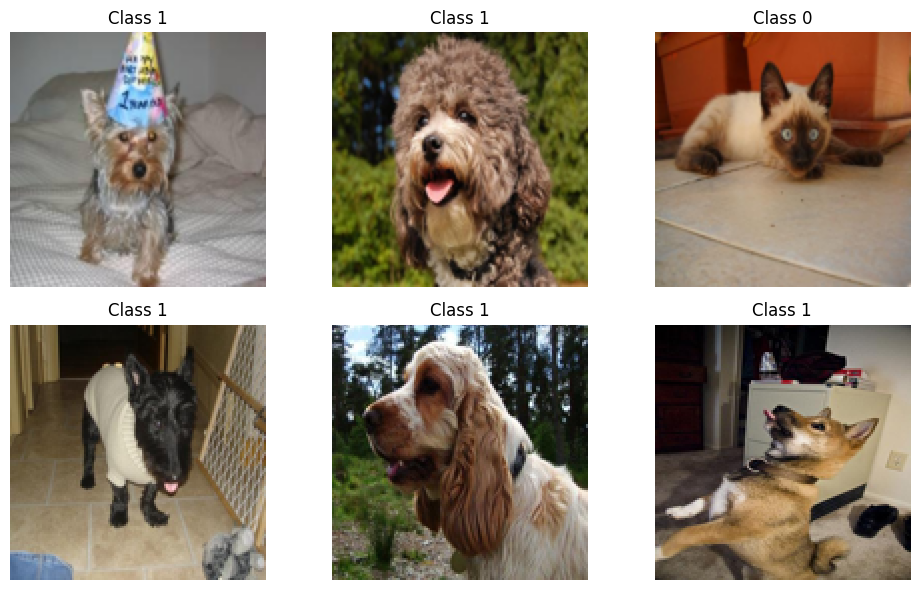

In [11]:
print("Supriya K_24BAD118")
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.model_selection import train_test_split

zip_path = "/content/DL_Ex3.zip"
extract_path = "/content/DL_Ex3"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

train_df = pd.read_csv(os.path.join(extract_path, "train.csv"))
val_df = pd.read_csv(os.path.join(extract_path, "val.csv"))

IMG_SIZE = 128

def load_images(dataframe):
    images = []
    labels = []

    for _, row in dataframe.iterrows():
        image_path = os.path.join(extract_path, row["image:FILE"])
        image = Image.open(image_path).convert("RGB")
        image = image.resize((IMG_SIZE, IMG_SIZE))
        images.append(np.array(image))
        labels.append(row["category"])

    return np.array(images), np.array(labels)

X_train_full, y_train_full = load_images(train_df)
X_val, y_val = load_images(val_df)

X_train_full = X_train_full.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0

X_train, X_test, y_train, y_test = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

plt.figure(figsize=(10, 6))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(X_train[i])
    plt.title(f"Class {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
print("Supriya K_24BAD118")
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(128, 128, 3)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.5),

    Dense(2, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Supriya K_24BAD118


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,898 (12.61 MB)

 Trainable params: 3,304,898 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Supriya K_24BAD118
Epoch 1/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 6s 323ms/step - accuracy: 0.6000 - loss: 0.8313 - val_accuracy: 0.6571 - val_loss: 0.6480
Epoch 2/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 361ms/step - accuracy: 0.6545 - loss: 0.6691 - val_accuracy: 0.6571 - val_loss: 0.6602
Epoch 3/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 305ms/step - accuracy: 0.6545 - loss: 0.6587 - val_accuracy: 0.6571 - val_loss: 0.6443
Epoch 4/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 318ms/step - accuracy: 0.6545 - loss: 0.6375 - val_accuracy: 0.6571 - val_loss: 0.6300
Epoch 5/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 316ms/step - accuracy: 0.6545 - loss: 0.5947 - val_accuracy: 0.6571 - val_loss: 0.6338
Epoch 6/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 306ms/step - accuracy: 0.7091 - loss: 0.5252 - val_accuracy: 0.6000 - val_loss: 0.6338
Epoch 7/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 6s 383ms/step - accuracy: 0.7636 - loss: 0.4736 - val_accuracy: 0.6000 - val_loss: 0.6954
Epoch 8/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 333ms/step - accuracy: 0.8000 - loss: 0.4029

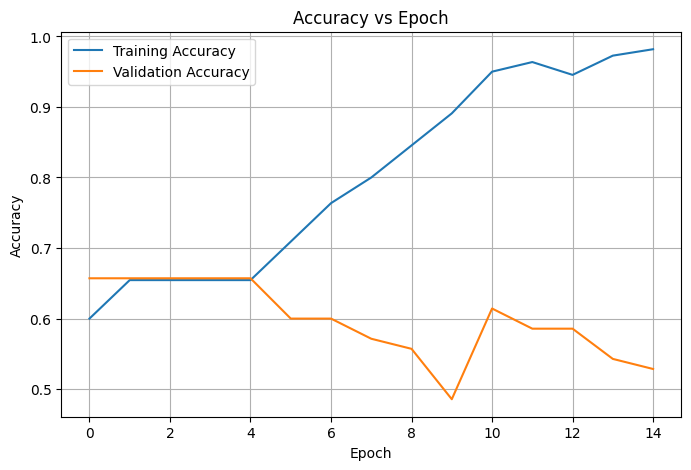

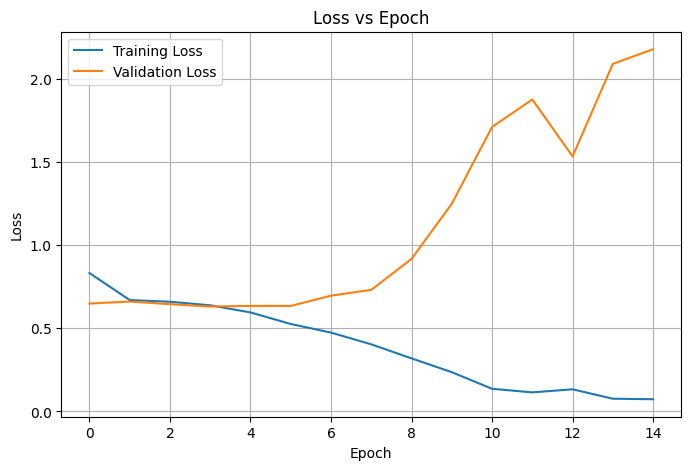

In [13]:
print("Supriya K_24BAD118")
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=16,
    verbose=1
)

train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Training Accuracy:", train_accuracy[-1])
print("Validation Accuracy:", val_accuracy[-1])
print("Training Loss:", train_loss[-1])
print("Validation Loss:", val_loss[-1])
print("Testing Accuracy:", test_accuracy)

plt.figure(figsize=(8, 5))

plt.plot(train_accuracy, label="Training Accuracy")
plt.plot(val_accuracy, label="Validation Accuracy")

plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.show()

plt.figure(figsize=(8, 5))

plt.plot(train_loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")

plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.show()

Supriya K_24BAD118
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step
Confusion Matrix:
[[ 5 14]
 [ 9 27]]


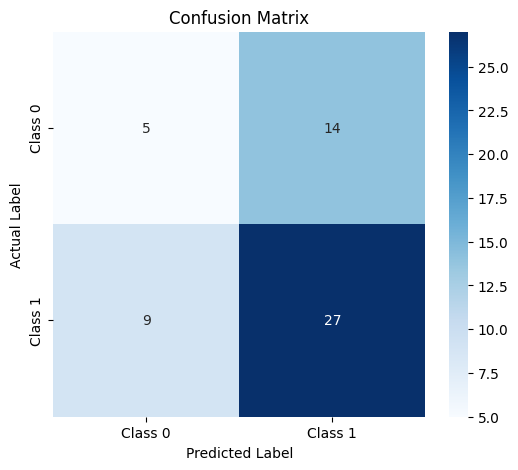

              precision    recall  f1-score   support

     Class 0       0.36      0.26      0.30        19
     Class 1       0.66      0.75      0.70        36

    accuracy                           0.58        55
   macro avg       0.51      0.51      0.50        55
weighted avg       0.55      0.58      0.56        55



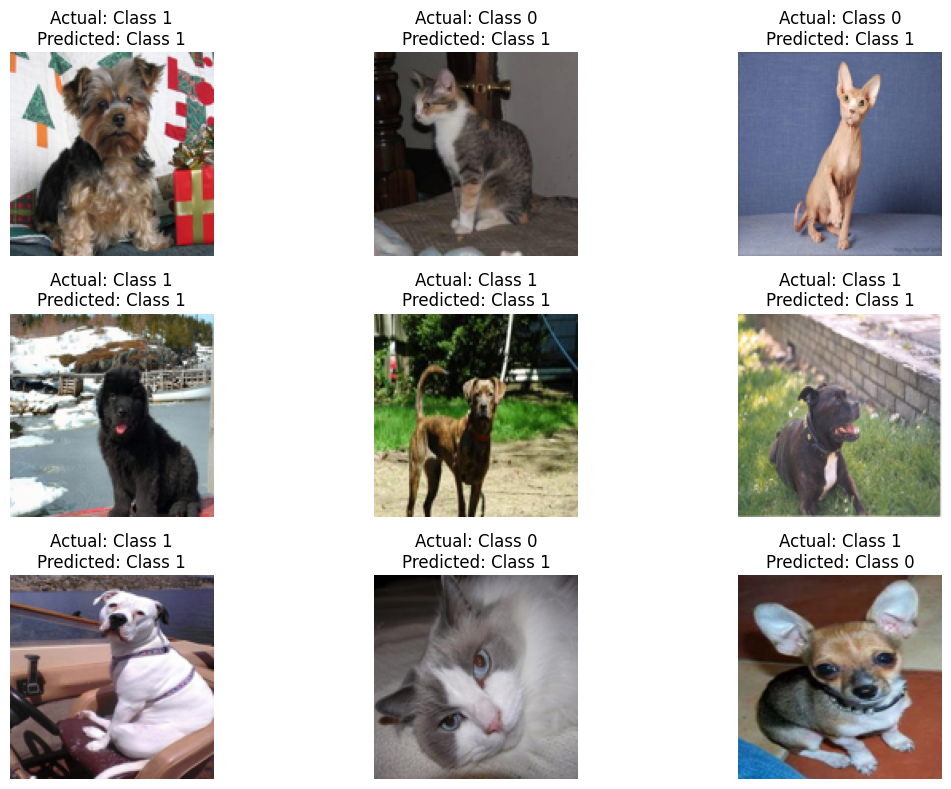

Number of Misclassified Images: 23


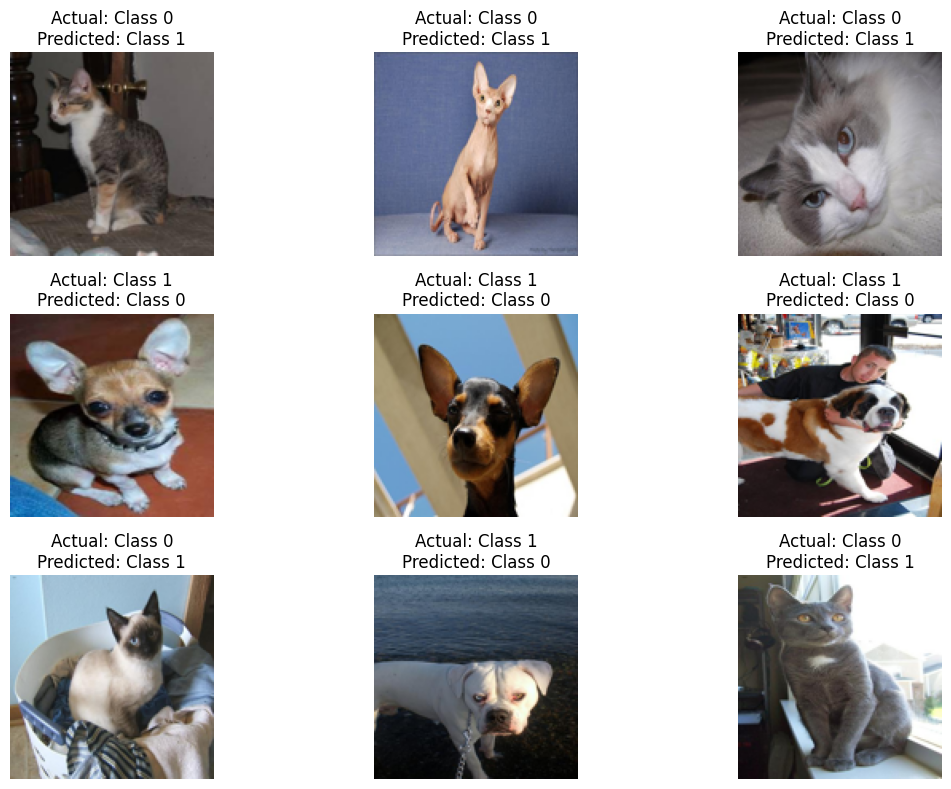

Training Accuracy   : 98.18 %
Validation Accuracy : 52.86 %
Testing Accuracy    : 58.18 %
Training Loss       : 0.0733
Validation Loss     : 2.176
Misclassified Images: 23


In [14]:
print("Supriya K_24BAD118")
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_pred_probability = model.predict(X_test)
y_pred = np.argmax(y_pred_probability, axis=1)

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")

plt.show()

print(classification_report(
    y_test,
    y_pred,
    target_names=["Class 0", "Class 1"]
))

plt.figure(figsize=(12, 8))

for i in range(min(9, len(X_test))):

    plt.subplot(3, 3, i + 1)

    plt.imshow(X_test[i])

    actual = y_test[i]
    predicted = y_pred[i]

    plt.title(
        f"Actual: Class {actual}\nPredicted: Class {predicted}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

misclassified = np.where(y_test != y_pred)[0]

print("Number of Misclassified Images:", len(misclassified))

plt.figure(figsize=(12, 8))

num_images = min(9, len(misclassified))

for i in range(num_images):

    index = misclassified[i]

    plt.subplot(3, 3, i + 1)

    plt.imshow(X_test[index])

    plt.title(
        f"Actual: Class {y_test[index]}\n"
        f"Predicted: Class {y_pred[index]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

print("Training Accuracy   :", round(train_accuracy[-1] * 100, 2), "%")
print("Validation Accuracy :", round(val_accuracy[-1] * 100, 2), "%")
print("Testing Accuracy    :", round(test_accuracy * 100, 2), "%")
print("Training Loss       :", round(train_loss[-1], 4))
print("Validation Loss     :", round(val_loss[-1], 4))
print("Misclassified Images:", len(misclassified))